# Lab 5: Rule-Based Methods

In this tutorial we will see an application of two methods among those seen during class:
* BELLATREX
* inTrees

### SET UP THE ENVIRONMENT

The BELLATREX repository from Dedja et al. is available at this [link](https://github.com/Klest94/Bellatrex).

The inTrees code is implemented in R but we can use a Python wrapper that has been implemented. The code is available at this [link](https://github.com/softwaredeng/inTrees).\
However, the wrapper code contains a few bugs and incompatibility errors. You can retrieve a fixed version of the code [here](https://drive.google.com/drive/folders/1iKhyscDJxlLVvvc4Q3vnFMIm_CEnOEzr?usp=sharing).



You can download the `environment_rulebased.yml` file and run the following commands to create the environment:

`conda env create -f environment_rulebased.yml` 

This will create an environment named `rulebased`, that can be used to execute the code in this notebook.\

In [2]:
!conda env create -f environment_rulebased.yml

Solving environment: failed

ResolvePackageNotFound: 
  - m2w64-tcl==8.6.5=3
  - openssl==3.3.1=h2466b09_2
  - libblas==3.9.0=23_win64_mkl
  - libffi==3.4.2=h8ffe710_5
  - m2w64-mpfr==3.1.4=4
  - ucrt==10.0.22621.0=h57928b3_0
  - libsqlite==3.46.0=h2466b09_0
  - m2w64-xz==5.2.2=2
  - m2w64-pcre2==10.34=0
  - m2w64-wineditline==2.101=5
  - m2w64-libvorbis==1.3.5=2
  - m2w64-bwidget==1.9.10=2
  - m2w64-libpng==1.6.21=2
  - m2w64-speexdsp==1.2rc3=3
  - m2w64-gmp==6.1.0=2
  - msys2-conda-epoch==20160418=1
  - libzlib==1.3.1=h2466b09_1
  - tk==8.6.13=h5226925_1
  - libhwloc==2.11.1=default_h8125262_1000
  - intel-openmp==2024.2.1=h57928b3_1083
  - m2w64-libtiff==4.0.6=2
  - r-base==4.1.3=h22dd5fe_15
  - m2w64-fftw==3.3.4=6
  - rpy2==3.5.11=py310r41hd22fa5f_3
  - python==3.10.14=h4de0772_0_cpython
  - m2w64-tk==8.6.5=3
  - m2w64-libxml2==2.9.3=3
  - tzlocal==5.2=py310h5588dad_0
  - vc==14.3=h8a93ad2_20
  - m2w64-expat==2.1.1=2
  - m2w64-gsl==2.1=2
  - m2w64-zlib==1.2.8=10
  - libxml2==2.12.7

In [4]:
!pip install bellatrex

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.8/121.8 kB 3.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.7/835.7 kB 15.8 MB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.1/23.1 MB 53.2 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 237.6/237.6 kB 22.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 142.4/142.4 kB 11.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 53.0 MB/s eta 0:00:0000:010:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 301.8/301.8 kB 17.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.5/98.5 kB 13.7 MB/s eta 0:00:00
  Created wheel for ecos: filename=ecos-2.0.14-cp310-cp310-macosx_11_0_arm64.whl size=72264 sha256=5bedaae9944c32ba0c7c077de153e5382cd4d696c7454166b21b50b19f04ff63
  Stored in directory: /U

In [5]:
!pip install dearpygui==1.6.2
!pip install dearpygui-ext==0.9.5

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 8.1 MB/s eta 0:00:00ta 0:00:01


## Part 1: BELLATREX

### BELLATREX

#### 1. Imports

In [6]:
import os
import bellatrex as btrex
print(btrex.__version__)

0.2.2


In [7]:
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import train_test_split

from bellatrex.datasets import load_binary_data
from bellatrex import BellatrexExplain
from bellatrex.utilities import predict_helper

import warnings
warnings.filterwarnings("ignore")

#### 2. Load the data

The dataset that we will use is the **blood donations** dataset, provided in the BELLATREX repository for the binary classification example.

The data is composed of four predictors (X):
* `months-last-donation`: months passed since the last donation
* `tot-donations`: total number of donations
* `tot-donated-ml`: total millimeters of blood donated
* `months-first-donation`: months passed since the first donation

And the binary target variable (y) is:
* `donor-in-2007`: whether the person has been a donor in 2007

We can load the features (X) and targets (y) using the utility function in the BELLATREX repository.

In [8]:
X, y = load_binary_data(return_X_y=True)

We can take a look at the dataset.

In [9]:
X

,months-last-donation,tot-donations,tot-donated-ml,months-first-donation
0,9,8,2000,38
1,2,1,250,2
2,16,5,1250,71
3,23,1,250,23
4,4,6,1500,23
...,...,...,...,...
743,2,10,2500,49
744,11,3,750,16
745,2,3,750,14
746,11,1,250,11


In [10]:
y

0      1
1      0
2      0
3      0
4      1
      ..
743    0
744    1
745    0
746    0
747    1
Name: donor-in-2007, Length: 748, dtype: int64

Finally we can split the data into train and test datasets using sklearn.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

#### 3. Instantiate and fit the Random Forest model

In [12]:
clf = RandomForestClassifier(n_estimators=100, min_samples_split=5, random_state=0)

In [13]:
clf.fit(X_train, y_train)
print('Model fitting complete.')

Model fitting complete.


#### 4. Instantiate and fit the BELLATREX model

Now we can fit Bellatrex on the training data.

In [14]:
# fit RF here. The hyperparameters are given      
Btrex_fitted = BellatrexExplain(clf, set_up='auto',
                                p_grid={"n_clusters": [1, 2, 3]},
                                verbose=3).fit(X_train, y_train)

Model is already fitted, building explanation.
oracle_sample is: None
Automatically setting prediction task to: binary


#### 5. Make predictions, output explanations

Then we can loop through the instances of the test set, make predictions using the Bellatrex local method and use:

* `plot_overview()` to get a representation of the tree learners, and of the selected rules; GUI is available for this plotting method (set the paramter plot_gui = True).
* `plot_visuals()` to visualise the selected rules in a more use friendly way.

Explaining sample i=0
best params: {'n_clusters': 2, 'n_dims': None, 'n_trees': 100}
Achieved fidelity: 0.9705
final trees indices: [78, 86]
final cluster sizes: [54 46]
Bellatrex prediction: 0.1314
Black box prediction: 0.1019
##########################################################


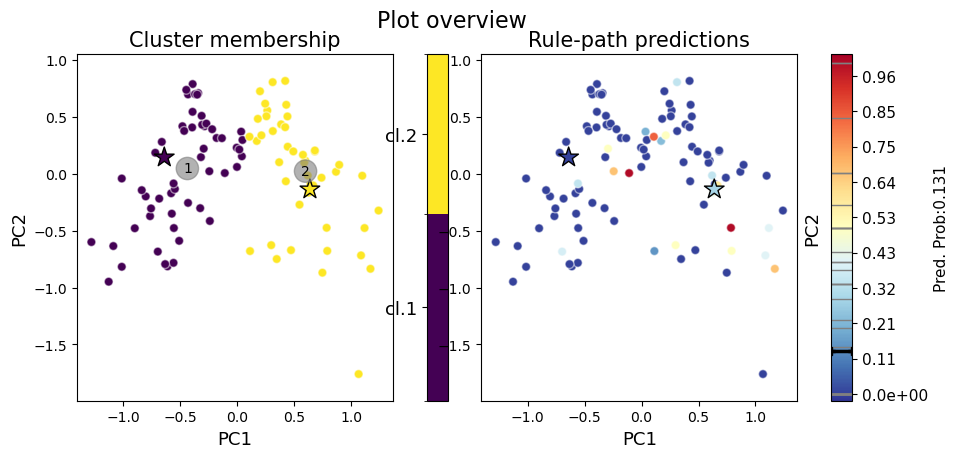

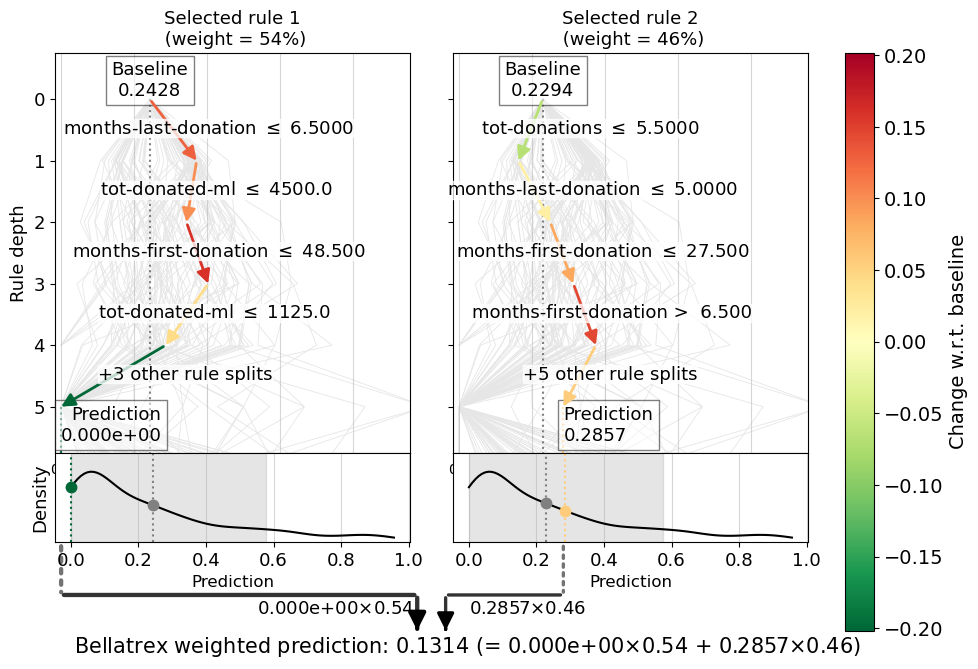

Explaining sample i=1
best params: {'n_clusters': 2, 'n_dims': None, 'n_trees': 60}
Achieved fidelity: 0.9095
final trees indices: [4, 28]
final cluster sizes: [46 14]
Bellatrex prediction: 0.3472
Black box prediction: 0.4377
##########################################################


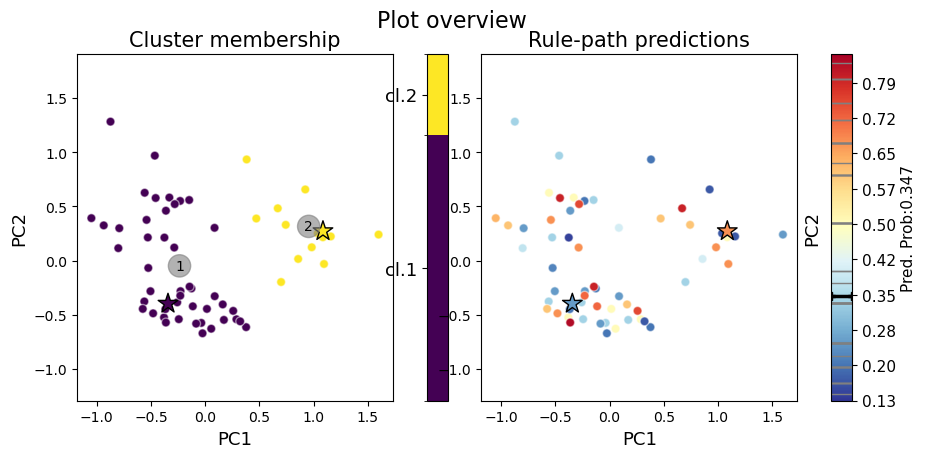

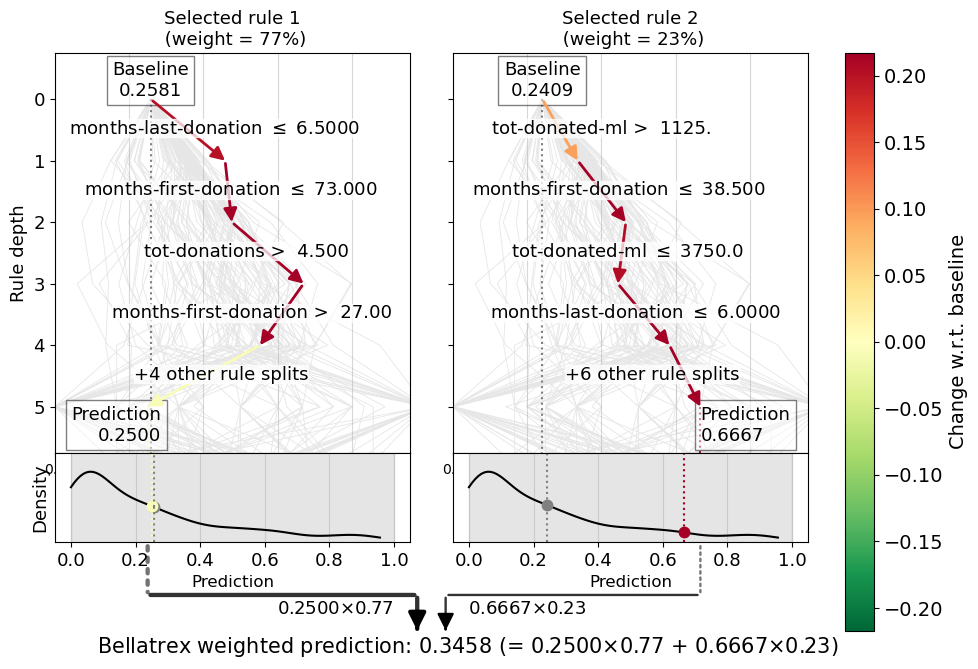

In [15]:
N_TEST_SAMPLES = 2
for i in range(N_TEST_SAMPLES):

    print(f"Explaining sample i={i}")

    y_train_pred = predict_helper(clf, X_train) # calls, predict or predict_proba, depending on the underlying model

    tuned_method = Btrex_fitted.explain(X_test, i)

    tuned_method.plot_overview(plot_gui=False,
                               show=True)


    tuned_method.plot_visuals(plot_max_depth=5,
                              preds_distr=y_train_pred,
                              conf_level=0.9,
                              tot_digits=4)

## Part 2: inTrees

First of all, we need to set the following variable to the path to the inTrees folder on our laptop.

In [16]:
# You need to change this to your path
PATH_INTREES="/inTrees/"

#### 1. Imports

In [12]:
import sys
sys.path.append(PATH_INTREES)
os.environ["R_HOME"] = f"{os.environ['CONDA_PREFIX']}\\Lib\\R"

In [13]:
import numpy as np
from constructors.inTrees import inTreesClassifier
from constructors.treeconstructor import CARTConstructor
from sklearn.metrics import confusion_matrix
from decisiontree import DecisionTree
import time

#### 2. Define data and initialize useful objects

In [14]:
conf_matrices, avg_nodes, times = {}, {}, {}
conf_matrices['inTrees'], avg_nodes['inTrees'], times['inTrees'] = [], [], []

We are going to use the same dataset as for the BELLATREX example.

In [15]:
df_train = X_train.copy()
df_train[y_train.name] = y_train

In [16]:
df_train

,months-last-donation,tot-donations,tot-donated-ml,months-first-donation,donor-in-2007
242,14,5,1250,28,0
533,12,13,3250,59,0
315,16,7,1750,64,0
12,14,2,500,21,1
161,14,7,1750,26,0
...,...,...,...,...,...
707,11,2,500,25,0
192,7,11,2750,89,0
629,8,2,500,16,0
559,23,6,1500,70,0


In [17]:
feature_cols = df_train.columns.values[:-1]
label_col = df_train.columns.values[-1]
print(feature_cols)
print(label_col)

['months-last-donation' 'tot-donations' 'tot-donated-ml'
 'months-first-donation']
donor-in-2007


#### 3. Initialize the CART algorithm to construct the tree ensemble

In [18]:
algorithm = CARTConstructor()

print(f"Algorithm: {algorithm}")
start = time.time()
clf = algorithm.construct_classifier(df_train, feature_cols, label_col, param_opt=False)
end = time.time()
print(f"Total time: {end-start:.2f} s")

Algorithm: <constructors.treeconstructor.CARTConstructor object at 0x0000017B737DA7D0>
Total time: 0.01 s


In [19]:
predictions = clf.evaluate_multiple(X_test).astype(int)

conf_matrix = confusion_matrix(y_test, predictions)
print(f"Confusion matrix: \n{conf_matrix}")

diagonal_sum = sum([conf_matrix[i][i] for i in range(len(conf_matrix))])
norm_diagonal_sum = sum([float(conf_matrix[i][i]) / float(sum(conf_matrix[i])) for i in range(len(conf_matrix))])
total_count = np.sum(conf_matrix)
print(f"Accuracy: {float(diagonal_sum) / float(total_count):.2f}")
print(f"Balanced accuracy: {float(norm_diagonal_sum) / float(conf_matrix.shape[0]):.2f}")

print('Number of nodes:', clf.count_nodes())

Confusion matrix: 
[[138  32]
 [ 36  19]]
Accuracy: 0.70
Balanced accuracy: 0.58
Number of nodes: 241


#### 4. Instantiate the inTrees model

In [20]:
inTrees_clf = inTreesClassifier()

#### 5. Make predictions, output explanations

In [21]:
_constructors = [CARTConstructor()]
start = time.time()
# You may need to change the lib_loc depending on your R installation
orl = inTrees_clf.construct_rule_list(df_train, label_col, _constructors, nr_bootstraps=25, lib_loc='C:/Program Files/R/R-4.4.1/library')
end = time.time()
print(f"Time for constructing rule list: {end-start:.2f} s")

877 rules (length<=6) were extracted from the first 50 trees.
Time for constructing rule list: 281.98 s


In [22]:
predictions = orl.evaluate_multiple(X_test).astype(int)

conf_matrix_inTrees = confusion_matrix(y_test, predictions)
print(f"Confusion matrix: \n{conf_matrix_inTrees}")
diagonal_sum = sum([conf_matrix[i][i] for i in range(len(conf_matrix_inTrees))])
norm_diagonal_sum = sum([float(conf_matrix_inTrees[i][i]) / float(sum(conf_matrix_inTrees[i])) for i in range(len(conf_matrix_inTrees))])
total_count = np.sum(conf_matrix_inTrees)
correct = 0
for i in range(len(conf_matrix_inTrees)):
    correct += conf_matrix_inTrees[i][i] + conf_matrix_inTrees[i][max(i - 1, 0)] * ((i - 1) >= 0) + \
                conf_matrix_inTrees[i][min(i + 1, len(conf_matrix_inTrees[i]) - 1)] * ((i + 1) <= len(conf_matrix_inTrees[i]) - 1)
# print 'Accuracy [-1, +1]:', float(correct) / float(total_count)
print(f"Accuracy: {float(diagonal_sum) / float(total_count):.2f}")
print(f"Balanced accuracy: {float(norm_diagonal_sum) / float(conf_matrix_inTrees.shape[0]):.2f}")

print(f"Number of nodes: {len(orl.rule_list)}")

Confusion matrix: 
[[145  25]
 [ 31  24]]
Accuracy: 0.70
Balanced accuracy: 0.64
Number of nodes: 43
